In [9]:
%pip install -q "qiskit==2.2.3" "qiskit-algorithms==0.4.0" "qiskit-nature==0.7.2" "pyscf==2.10.0"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for package in ["qiskit", "qiskit-algorithms", "qiskit-nature", "pyscf", "numpy", "scipy", "scikit-learn"]:
    print(package, version(package))
print("설치 완료: 다음 실행 코드 셀로 이동합니다.")

ERROR: Operation cancelled by user
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 109, in _run_wrapper
    status = _inner_run()
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 102, in _inner_run
    return self.run(options, args)
           ~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 106, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 478, in run
    requirement_set = resolver.resolve(
        reqs, check_supported_wheels=not options.target_dir
    )
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/resolution/resolvelib/resolver.py", line 103, in resolve
    result = self._result = resolver.resolve(
                            ~~~~~~~~~~~~~~~~^
        collected.requirements, max_rounds=limit_how_comp

Running Logistics VQE Optimization...

Logistics Optimization Results
선택 경로      : 0 → 1 → 2 → 3 → 0
선택 경로 비용 : 18.0 / 전수 탐색 최소 비용: 18.0
선택 경로 확률 : 0.9999
최적화된 평균 비용: 18.000297
검증 통과: VQE가 최적의 물류 배송 경로를 정확히 찾아냈습니다.


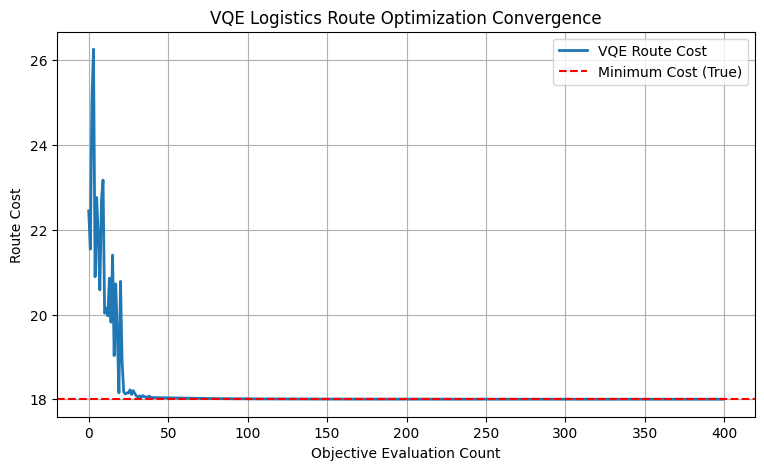

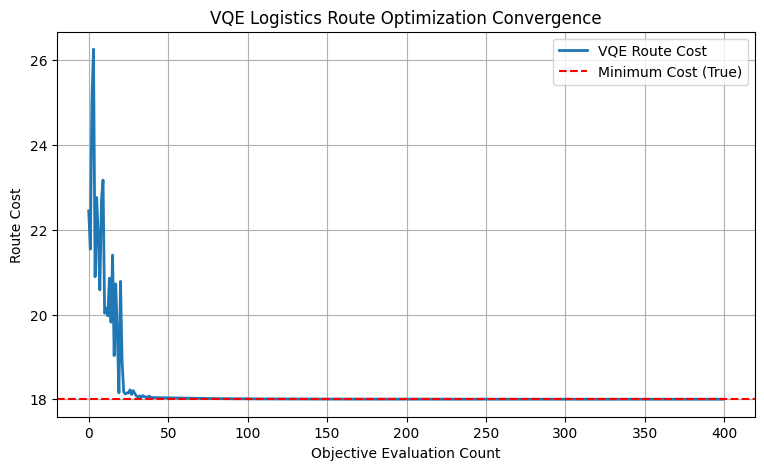

In [10]:
%matplotlib inline
import itertools
import numpy as np
import matplotlib.pyplot as plt

from qiskit.quantum_info import SparsePauliOp, Operator, Statevector
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import COBYLA


# ==============================================================================
# STEP 2. 물류 배송 경로(Route) 및 비용(Cost) 정의
# ==============================================================================
# 창고 0번에서 출발하여 배송지 1, 2, 3을 한 번씩 방문하고 다시 0으로 돌아오는 경로를 설계합니다.
# 총 6개의 후보 경로(3! = 6)가 존재하며, 3큐비트(2^3 = 8개 상태)에 매핑합니다.
distance = np.array([
    [0, 4, 7, 6],
    [4, 0, 3, 8],
    [7, 3, 0, 5],
    [6, 8, 5, 0]
])

# 모든 배송 순서의 경우의 수를 구하고 시작/끝에 창고(0)를 추가
routes = [(0,) + p + (0,) for p in itertools.permutations([1, 2, 3])]

# 각 경로별 총 이동 거리(비용) 계산
costs = np.array([sum(distance[a, b] for a, b in zip(r, r[1:])) for r in routes], dtype=float)


# ==============================================================================
# STEP 3. 비용 함수 해밀턴산(Hamiltonian) 구성 (미사용 상태 벌점 부여)
# =================================================}=============================
# 3큐비트는 총 8개의 상태(000~111)를 표현할 수 있지만, 유효한 경로는 6개뿐입니다.
# 유효하지 않은 나머지 2개 상태(인덱스 6, 7)에는 막대한 벌점(Penalty)을 주어 선택되지 않게 합니다.
diagonal = np.full(8, costs.max() + 20)
diagonal[:len(routes)] = costs  # 0~5번 인덱스에는 실제 경로 비용 대입

# 대각 행렬을 파울리 연산자 기반의 해밀턴산(H)으로 변환
H = SparsePauliOp.from_operator(Operator(np.diag(diagonal)))


# ==============================================================================
# STEP 4. 변분 회로(Ansatz) 및 파라미터 설계
# ==============================================================================
# 3개의 큐비트와 3개의 레이어(Layer)로 구성된 양자 회로(Ansatz)를 설계합니다.
# 총 9개($3 \times 3$)의 회전 파라미터(θ)를 사용합니다.
theta = ParameterVector("θ", 9)

ansatz = QuantumCircuit(3)
for layer in range(3):
    for q in range(3):
        ansatz.ry(theta[3 * layer + q], q)
    if layer < 2:
        ansatz.cx(0, 1)
        ansatz.cx(1, 2)


# ==============================================================================
# STEP 5. 학습 기록(History)을 위한 콜백 함수 정의
# ==============================================================================
# VQE 최적화 과정에서 매 스텝마다 계산되는 비용 값을 실시간으로 수집하여
# 학습 곡선(Convergence Curve)을 그릴 수 있도록 리스트에 저장합니다.
history = []

def callback_fn(count, params, value, meta):
    history.append(float(value))


# ==============================================================================
# STEP 6. VQE 알고리즘 초기화 및 최적화 실행
# ==============================================================================
# - StatevectorEstimator: CPU 상에서 이상적인 양자 기댓값 계산
# - COBYLA: 미분 없이 비용을 줄여나가는 고전 최적화 알고리즘
# - initial_point: 난수를 이용해 9개의 파라미터 초기값 설정
solver = VQE(
    estimator=StatevectorEstimator(seed=42),
    ansatz=ansatz,
    optimizer=COBYLA(maxiter=400),
    initial_point=np.random.default_rng(42).uniform(0, 2 * np.pi, 9),
    callback=callback_fn
)

print("=" * 60)
print("Running Logistics VQE Optimization...")
print("=" * 60)
result = solver.compute_minimum_eigenvalue(H)


# ==============================================================================
# STEP 7. 결과 분석 및 최적 경로 디코딩
# ==============================================================================
# 최적화가 완료된 파라미터를 회로에 대입하여 최종 양자 상태와 확률 분포를 구합니다.
optimal_circuit = ansatz.assign_parameters(result.optimal_parameters)
state = Statevector.from_instruction(optimal_circuit)
prob = state.probabilities()

# 확률이 가장 높은 유효 경로 인덱스 선택
best = int(np.argmax(prob[:len(routes)]))

print("\n" + "=" * 60)
print("Logistics Optimization Results")
print("=" * 60)
print("선택 경로      :", " → ".join(map(str, routes[best])))
print(f"선택 경로 비용 : {costs[best]} / 전수 탐색 최소 비용: {costs.min()}")
print(f"선택 경로 확률 : {round(float(prob[best]), 4)}")
print(f"최적화된 평균 비용: {round(float(result.eigenvalue.real), 6)}")

# 결과 검증
assert costs[best] == costs.min(), "최적 경로 선택 실패!"
assert float(result.eigenvalue.real) < costs.min() + 0.02, "최적 비용 수렴 실패!"
print("검증 통과: VQE가 최적의 물류 배송 경로를 정확히 찾아냈습니다.")


# ==============================================================================
# STEP 8. 결과 시각화 (Learning Curve)
# ============================================================--==============
# 최적화 평가 횟수에 따른 경로 비용 감소 추이를 그래프로 시각화합니다.
fig = plt.figure(figsize=(9, 5))

plt.plot(history, label="VQE Route Cost", linewidth=2)
plt.axhline(costs.min(), color="red", linestyle="--", label="Minimum Cost (True)")

plt.xlabel("Objective Evaluation Count")
plt.ylabel("Route Cost")
plt.title("VQE Logistics Route Optimization Convergence")
plt.grid(True)
plt.legend()

display(fig)
plt.show()